   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 35.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 31.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pymoo]


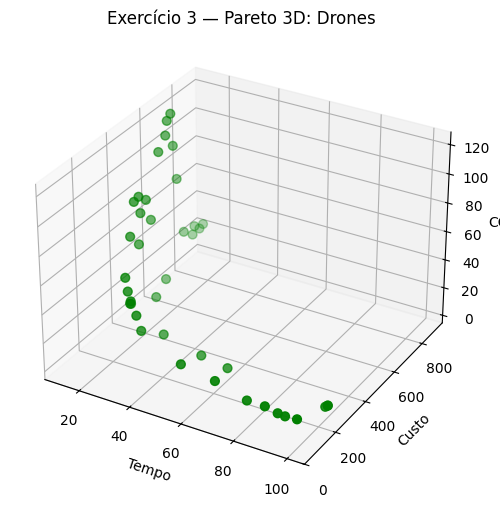

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

class DroneProblem(ElementwiseProblem):
    def __init__(self):
        super().__init__(n_var=2, n_obj=3, xl=np.array([10.0, 1.0]), xu=np.array([80.0, 5.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        velocidade, carga = x[0], x[1]
        f1_tempo = 1000.0 / velocidade
        f2_custo = (velocidade ** 2) * 0.1 + (carga * 50)
        f3_co2 = (velocidade * 1.5) / carga
        out["F"] = [f1_tempo, f2_custo, f3_co2]

res3 = minimize(DroneProblem(), NSGA2(pop_size=40), termination=('n_gen', 50), seed=42)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(res3.F[:, 0], res3.F[:, 1], res3.F[:, 2], color='green', s=40)
ax.set_xlabel("Tempo")
ax.set_ylabel("Custo")
ax.set_zlabel("CO2")
plt.title("Exercício 3 — Pareto 3D: Drones")
plt.show()
